In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv('InternetSales.csv', encoding='latin1')


display(df.head())

/tmp/ipykernel_3364/1672965129.py:5: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('InternetSales.csv', encoding='latin1')


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [13]:
print(df['OrderDate'].head())
df['OrderDate'] = pd.to_datetime(df['OrderDate'], errors='coerce')
print("First sale:", df['OrderDate'].min())
print("Last sale:", df['OrderDate'].max())

0    1/19/2011
1    1/18/2013
2    1/18/2013
3     5/3/2013
4     5/3/2013
Name: OrderDate, dtype: object
First sale: 2010-12-29 00:00:00
Last sale: 2014-01-28 00:00:00


In [14]:
monthly_sales = (
    df.groupby(df['OrderDate'].dt.to_period('M'))['SalesAmount']
    .sum()
)

monthly_sales.index = monthly_sales.index.to_timestamp()

monthly_sales.head()

,SalesAmount
OrderDate,
2010-12-01,43421.0364
2011-01-01,469823.9148
2011-02-01,466334.9030
2011-03-01,485198.6594
2011-04-01,502073.8458


In [15]:

n = len(monthly_sales)

x = np.arange(n)
y = monthly_sales.values

slope, intercept = np.polyfit(x, y, 1)

trend = slope * x + intercept

future_x = np.arange(n, n + 60)
forecast = slope * future_x + intercept

future_dates = pd.date_range(
    start=monthly_sales.index[-1] + pd.offsets.MonthBegin(1),
    periods=60,
    freq='MS'
)

forecast_df = pd.DataFrame({
    'Month': future_dates,
    'ForecastSales': forecast
})

forecast_df.head(12)

,Month,ForecastSales
0,2014-02-01,1.326400e+06
1,2014-03-01,1.354800e+06
2,2014-04-01,1.383200e+06
3,2014-05-01,1.411600e+06
4,2014-06-01,1.440001e+06
5,2014-07-01,1.468401e+06
6,2014-08-01,1.496801e+06
7,2014-09-01,1.525201e+06
8,2014-10-01,1.553601e+06
9,2014-11-01,1.582001e+06


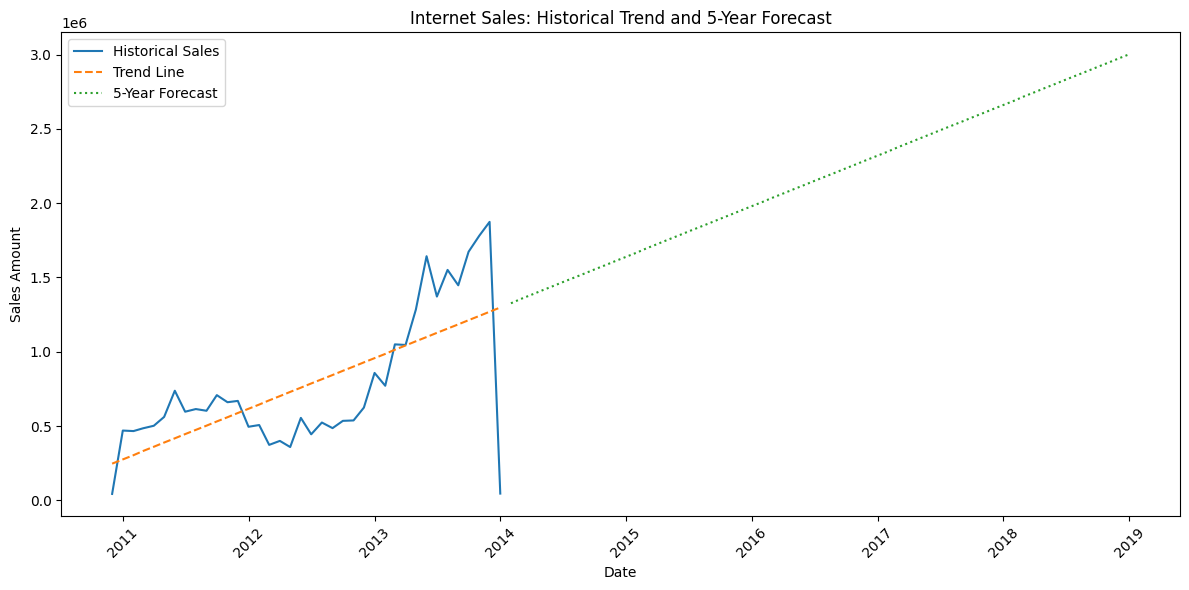

In [16]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    label='Historical Sales'
)

plt.plot(
    monthly_sales.index,
    trend,
    label='Trend Line',
    linestyle='--'
)

plt.plot(
    forecast_df['Month'],
    forecast_df['ForecastSales'],
    label='5-Year Forecast',
    linestyle=':'
)

plt.title('Internet Sales: Historical Trend and 5-Year Forecast')
plt.xlabel('Date')
plt.ylabel('Sales Amount')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [17]:
product_stats = (
    df.groupby('EnglishProductName')['SalesAmount']
    .agg(['sum', 'mean', 'count'])
    .sort_values('sum', ascending=False)
)

product_stats.columns = [
    'TotalSales',
    'AverageSales',
    'NumberOfSales'
]

product_stats.head(10)

,TotalSales,AverageSales,NumberOfSales
EnglishProductName,,,
"Mountain-200 Black, 46",1.373470e+06,2215.273465,620
"Mountain-200 Black, 42",1.363142e+06,2220.101129,614
"Mountain-200 Silver, 38",1.339463e+06,2247.420789,596
"Mountain-200 Silver, 46",1.301100e+06,2243.276032,580
"Mountain-200 Black, 38",1.294866e+06,2224.855913,582
"Mountain-200 Silver, 42",1.257435e+06,2245.418880,560
"Road-150 Red, 48",1.205877e+06,3578.270000,337
"Road-150 Red, 62",1.202299e+06,3578.270000,336
"Road-150 Red, 52",1.080638e+06,3578.270000,302


In [18]:
top_product = product_stats.iloc[0]

print("Top-selling product:", product_stats.index[0])
print("Total sales:", round(top_product['TotalSales'], 2))
print("Average sales:", round(top_product['AverageSales'], 2))
print("Number of sales records:", int(top_product['NumberOfSales']))

Top-selling product: Mountain-200 Black, 46
Total sales: 1373469.55
Average sales: 2215.27
Number of sales records: 620


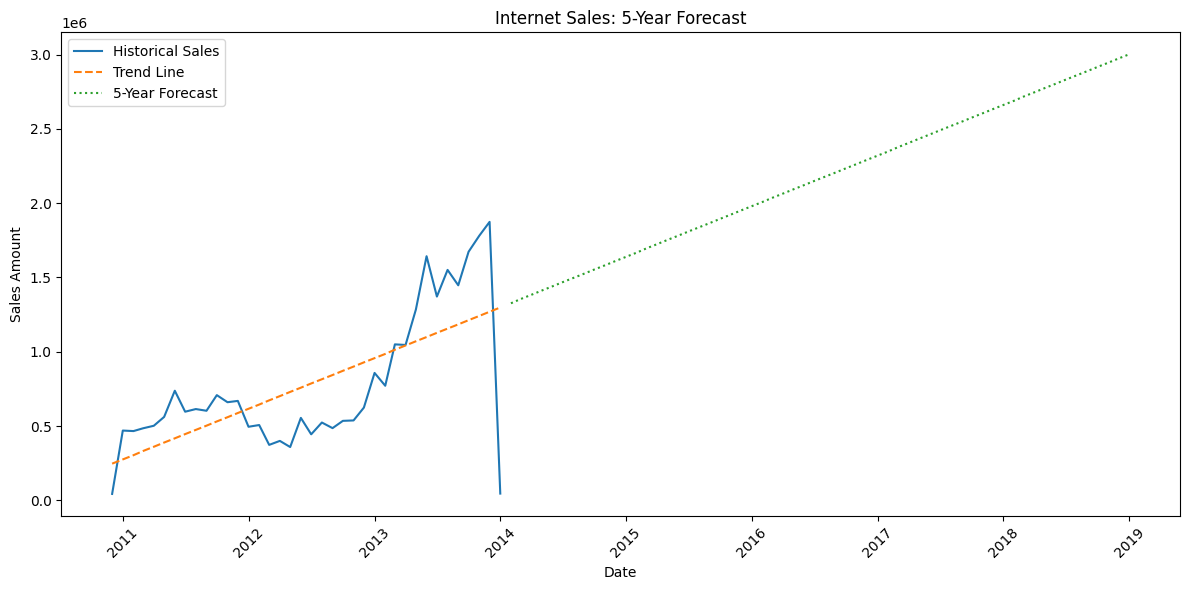

In [19]:
plt.figure(figsize=(12, 6))

plt.plot(monthly_sales.index, monthly_sales.values, label='Historical Sales')
plt.plot(monthly_sales.index, trend, linestyle='--', label='Trend Line')
plt.plot(forecast_df['Month'], forecast_df['ForecastSales'],
         linestyle=':', label='5-Year Forecast')

plt.title('Internet Sales: 5-Year Forecast')
plt.xlabel('Date')
plt.ylabel('Sales Amount')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('InternetSales_Forecast.pdf', format='pdf', bbox_inches='tight')
plt.show()